# Round 4 THINGS head (all 1854 concepts)

Linear(512, 1854) on the frozen pretrained CordsNet-R8 features (classifier input, steps 70-99). Initialization: the 548 concepts that overlap ImageNet from the ImageNet head (one matched class: copied; several: mean), the 1306 others from the Round 3 head. All rows then trained: CordsNet's weighted CE, true THINGS labels, AdamW (weight decay on the weights only), lr 1e-3 cosine to 0, 40 epochs.
Train 18,540 images (10 per concept), val 1,854 (1 per concept; 548 of overlapping concepts). Grid: mode (all rows trained / overlapping rows frozen) x weight decay (0, 0.01, 0.1, 1).

**Selected head: all rows trained, weight decay 0.1, epoch 21** (best val top-1 accuracy; `best_head_all_top1.pt`). Only this run is plotted.

Input: `Round4/outputs/things_head/cosine_ep40/` (`history.csv`, `results_all_top1.npz`; from `Round4/things_head/train_head.py`, copied from Torch).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CN = Path("~/Desktop/DynVision/CordsNet").expanduser()
out = CN / "Round4/outputs/things_head/cosine_ep40"
h = pd.read_csv(out / "history.csv")
r = np.load(out / "results_all_top1.npz")
mode, wd, best_epoch = str(r["mode"]), float(r["weight_decay"]), int(r["epoch"])
g = h[(h["mode"] == mode) & (h["weight_decay"] == wd)]
print(f"selected: mode {mode}, weight decay {wd:g}, epoch {best_epoch}")
g[g["epoch"].isin([0, best_epoch, 40])][["epoch", "train_top1", "val_top1", "val_top1_overlap", "val_top1_overlap_lenient",
                                          "val_top1_nonoverlap", "val_top5", "val_ce"]].round(4)

selected: mode all, weight decay 0.1, epoch 21


,epoch,train_top1,val_top1,val_top1_overlap,val_top1_overlap_lenient,val_top1_nonoverlap,val_top5,val_ce
82,0,0.7044,0.4439,0.0000,0.0000,0.6302,0.5879,40.6399
103,21,1.0000,0.6300,0.7281,0.7609,0.5888,0.8360,1.7159
122,40,1.0000,0.6273,0.7208,0.7573,0.5881,0.8360,1.7074


## Learning curves and accuracy over time

Left: top-1 accuracy over epochs (train; val for all concepts, overlapping and non-overlapping concepts). Middle: val top-1 accuracy of the selected head over the CE steps (142-200 ms). Right: val CE over epochs. Dashed vertical line: selected epoch. Epoch 0 (initialization only) is left out of the plots: overlapping concepts are at 0 and val CE is 40.6 (see the table above).

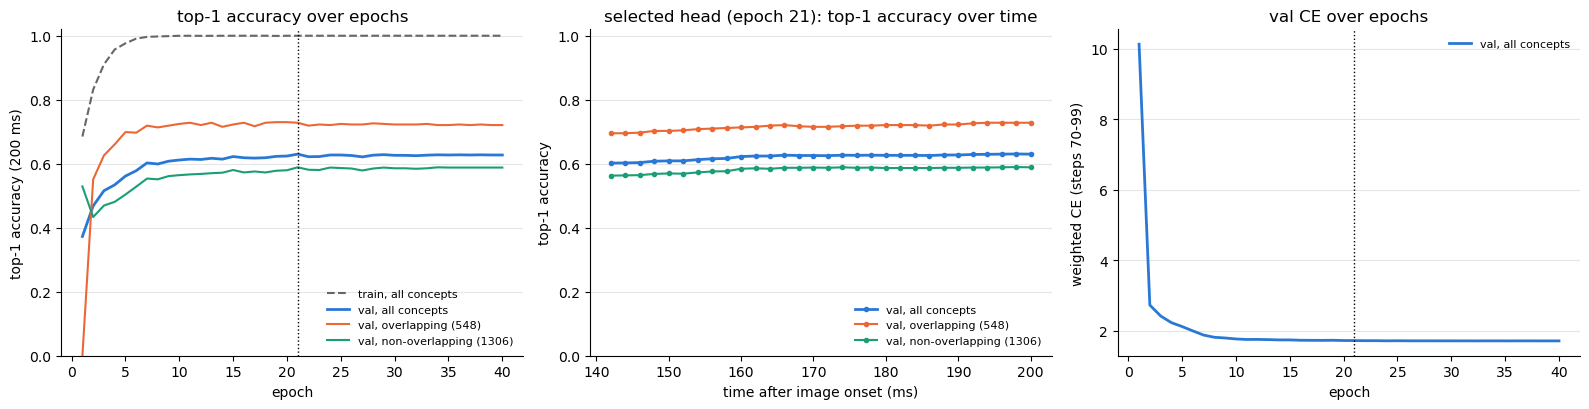

In [2]:
colors = {"all": "#2a78d6", "overlap": "#eb6834", "nonoverlap": "#1a9e77"}
e = g[g["epoch"] >= 1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
ax.plot(e["epoch"], e["train_top1"], color="0.4", lw=1.5, ls="--", label="train, all concepts")
ax.plot(e["epoch"], e["val_top1"], color=colors["all"], lw=2, label="val, all concepts")
ax.plot(e["epoch"], e["val_top1_overlap"], color=colors["overlap"], lw=1.5, label="val, overlapping (548)")
ax.plot(e["epoch"], e["val_top1_nonoverlap"], color=colors["nonoverlap"], lw=1.5, label="val, non-overlapping (1306)")
ax.set(xlabel="epoch", ylabel="top-1 accuracy (200 ms)", title="top-1 accuracy over epochs", ylim=(0, 1.02))

ax = axes[1]
t_ms = (r["steps"] + 1) * 2
ax.plot(t_ms, r["val_top1_t"], color=colors["all"], lw=2, marker="o", ms=3, label="val, all concepts")
ax.plot(t_ms, r["val_top1_overlap_t"], color=colors["overlap"], lw=1.5, marker="o", ms=3, label="val, overlapping (548)")
ax.plot(t_ms, r["val_top1_nonoverlap_t"], color=colors["nonoverlap"], lw=1.5, marker="o", ms=3, label="val, non-overlapping (1306)")
ax.set(xlabel="time after image onset (ms)", ylabel="top-1 accuracy", title=f"selected head (epoch {best_epoch}): top-1 accuracy over time", ylim=(0, 1.02))

ax = axes[2]
ax.plot(e["epoch"], e["val_ce"], color=colors["all"], lw=2, label="val, all concepts")
ax.set(xlabel="epoch", ylabel="weighted CE (steps 70-99)", title="val CE over epochs")

for i, ax in enumerate(axes):
    if i != 1:
        ax.axvline(best_epoch, color="k", ls=":", lw=1)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="lower right" if i < 2 else "upper right")
plt.tight_layout()
plt.show()

## Summary

(to be written after looking at the figure)